# Fig 3: Cooling technologies vs. rack power density (paper version)

Each source's stated range for each cooling technology, from `Data/generated/cooling_regimes.csv`. The x-axis is linear (0–520 kW). This is a forest-plot style figure: one thin bar per source, grouped into technology rows. It shows where sources overlap and where they disagree, instead of drawing hard thresholds (Section 2.3: *overlapping operating regimes, not universal thresholds*).

How each kind of value is drawn:
- **Stated range** (low and high): solid bar.
- **"Up to X"** (no low stated): short dotted lead-in ending in a cap at X. The source states a ceiling, not a range, so we don't draw down to the axis start.
- **"X and above"** (no high stated): solid bar from X, with an arrow.
- **Single design point** (`kW_typical` only): diamond.

Sources that don't name a sub-type (e.g. "air cooling" generally) get their own row instead of being assigned one.
Caveats for the caption: Vertiv 2024 chart values were read off a bar chart (approximate). Immersion research values are per tank, not per rack. Vendor figures are product claims.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator, MultipleLocator
from pathlib import Path
import paper_style as ps

ps.apply()
DATA = Path('../Data')
OUT = Path('../figures'); OUT.mkdir(exist_ok=True)

# Ordinal ramp by how close the liquid gets to the chip: air -> liquid-assisted air -> liquid
C_AIR, C_RDHX, C_LIQ = '#8a8984', '#7fcfb0', '#1baf7a'

## Data: map technologies to display rows

In [2]:
reg = pd.read_csv(DATA / 'generated/cooling_regimes.csv')

# display row, row colour, and a suffix added to the source label to keep sub-type information
ROW = {
    'Air cooling, traditional (perimeter CRAC/CRAH, raised floor, no containment)': ('Air: room-level', C_AIR, ''),
    'Air cooling with hot/cold aisle containment': ('Air: containment / in-row', C_AIR, ', containment'),
    'In-row / close-coupled air cooling': ('Air: containment / in-row', C_AIR, ', in-row/in-rack'),
    'Air cooling (general, type unspecified)': ('Air: type not stated', C_AIR, ''),
    'Rear-door heat exchanger': ('Rear-door heat exchanger', C_RDHX, ''),
    'Direct-to-chip liquid cooling, single-phase (cold plates)': ('Direct-to-chip liquid', C_LIQ, ', 1-phase'),
    'Direct-to-chip liquid cooling, two-phase': ('Direct-to-chip liquid', C_LIQ, ', 2-phase'),
    'Direct-to-chip liquid cooling (phase unspecified)': ('Direct-to-chip liquid', C_LIQ, ''),
    'Immersion cooling, single-phase': ('Immersion', C_LIQ, ', 1-phase'),
    'Immersion cooling, two-phase': ('Immersion', C_LIQ, ', 2-phase'),
    'Immersion cooling (phase unspecified)': ('Immersion', C_LIQ, ''),
    'Liquid cooling (type unspecified)': ('Liquid: type not stated', C_LIQ, ''),
}
ROW_ORDER = ['Air: room-level', 'Air: containment / in-row', 'Air: type not stated', 'Rear-door heat exchanger',
             'Direct-to-chip liquid', 'Immersion', 'Liquid: type not stated']

SHORT_SOURCE = {  # source -> short label
    'Servnet tracker (2026)': 'Servnet 2026', 'SERES rack densities (2026)': 'SERES 2026',
    'Uptime Cooling Systems Survey (2024)': 'Uptime survey 2024', 'Schneider Electric blog (2021)': 'Schneider 2021',
    'Vertiv containment article (2025)': 'Vertiv 2025', 'Chakraborty et al., UC Davis WCEC (2026)': 'UC Davis 2026',
    'Vertiv WP (2024), Fig.': 'Vertiv 2024 (chart)', 'Vertiv WP (2024)': 'Vertiv 2024',
    'Schneider Electric blog (2011)': 'Schneider 2011', 'Uptime Institute journal (2020)': 'Uptime 2020',
    'ENERGY STAR in-row/in-rack page (n.d.)': 'ENERGY STAR', 'Accelsius press release (2025)': 'Accelsius 2025',
    'GRC blog (2020)': 'GRC 2020', 'Shah & Tuma, Electronics Cooling (2024)': 'Shah & Tuma 2024',
}

def rdhx_type(note):
    n = str(note).lower()
    return ', passive' if 'type: passive' in n else ', active' if 'type: active' in n else ''

def per_tank(note):
    return ', per tank' if 'per tank' in str(note).lower() else ''

unmapped = set(reg['technology']) - set(ROW)
assert not unmapped, unmapped
reg['row'] = reg['technology'].map(lambda t: ROW[t][0])
reg['color'] = reg['technology'].map(lambda t: ROW[t][1])
reg['label'] = (reg['source'].map(SHORT_SOURCE).fillna(reg['source']) + reg['technology'].map(lambda t: ROW[t][2])
                + reg['notes'].map(rdhx_type).where(reg['row'] == 'Rear-door heat exchanger', '')
                + reg['notes'].map(per_tank))
reg['row_rank'] = reg['row'].map(ROW_ORDER.index)
reg = reg.sort_values(['row_rank', 'kW_high', 'kW_low'], na_position='first').reset_index(drop=True)
reg[['row', 'label', 'kW_low', 'kW_high', 'kW_typical', 'source_type']]

,row,label,kW_low,kW_high,kW_typical,source_type
0,Air: room-level,Schneider 2011,1.0,2.0,NaN,vendor
1,Air: room-level,ENERGY STAR,1.0,5.0,NaN,industry_body
2,Air: room-level,Vertiv 2024 (chart),3.0,15.0,NaN,vendor
3,Air: room-level,Uptime 2020,NaN,25.0,NaN,industry_body
4,Air: room-level,UC Davis 2026,NaN,35.0,NaN,research
5,Air: containment / in-row,"Vertiv 2024 (chart), containment",3.0,20.0,NaN,vendor
6,Air: containment / in-row,"Vertiv 2024 (chart), in-row/in-rack",5.0,30.0,NaN,vendor
7,Air: containment / in-row,"Servnet 2026, containment",NaN,40.0,NaN,blog
8,Air: containment / in-row,"UC Davis 2026, containment",NaN,44.0,NaN,research
9,Air: containment / in-row,"Schneider 2011, in-row/in-rack",NaN,50.0,NaN,vendor


## Figure

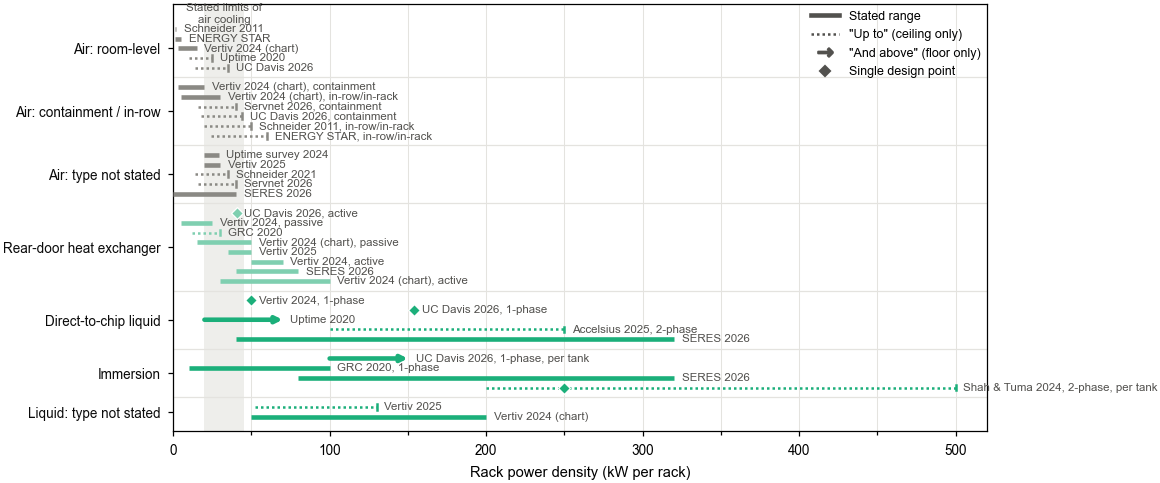

In [3]:
X_MIN, X_MAX = 0, 520   # linear axis; the highest stated value is 500 kW (Shah & Tuma, per tank)
AIR_LIMIT = (20, 45)  # where sources place the practical limit of air cooling (Uptime 2020/2024, Vertiv 2025, Schneider 2021, Servnet, UC Davis)
LINE_STEP, ROW_GAP = 1.0, 1.0

# y positions: one line per source, rows separated by a gap, first row at the top
ys, row_spans, y = [], {}, 0
for row in ROW_ORDER:
    idx = reg.index[reg['row'] == row]
    start = y
    for _ in idx:
        ys.append(y); y += LINE_STEP
    row_spans[row] = (start, y - LINE_STEP)
    y += ROW_GAP
reg['y'] = ys

fig, ax = plt.subplots(figsize=(ps.TEXT_W, 3.7))
ax.axvspan(*AIR_LIMIT, color=ps.GRID, alpha=0.6, lw=0, zorder=0)
ax.text(sum(AIR_LIMIT) / 2, -1.6, 'Stated limits of\nair cooling', ha='center', va='center',
        fontsize=5.5, color=ps.TEXT_2)

for _, r in reg.iterrows():
    lo, hi, typ, c, yy = r['kW_low'], r['kW_high'], r['kW_typical'], r['color'], r['y']
    if pd.notna(lo) and pd.notna(hi):
        ax.plot([max(lo, X_MIN), hi], [yy, yy], color=c, lw=2.2, solid_capstyle='butt', zorder=3)
        end = hi
    elif pd.notna(hi):   # 'up to X': a ceiling, so only a short lead-in to the cap
        ax.plot([hi / 2.5, hi], [yy, yy], color=c, lw=1.2, ls=(0, (1, 1.2)), zorder=3)
        ax.plot([hi, hi], [yy - 0.3, yy + 0.3], color=c, lw=1.2, zorder=3)
        end = hi
    elif pd.notna(lo):   # 'X and above'
        ax.annotate('', xy=(lo + 50, yy), xytext=(lo, yy), zorder=3,
                    arrowprops=dict(arrowstyle='-|>', color=c, lw=2.2, mutation_scale=6, shrinkA=0, shrinkB=0))
        end = lo + 50
    else:
        end = None
    if pd.notna(typ):
        ax.scatter(typ, yy, marker='D', s=16, color=c, edgecolor='white', linewidth=0.6, zorder=4)
        end = max(end or 0, typ)
    ax.text(end + 5, yy, r['label'], va='center', ha='left', fontsize=5.5, color=ps.TEXT_2)

ax.xaxis.set_major_locator(MultipleLocator(100))
ax.xaxis.set_minor_locator(MultipleLocator(50))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_xlim(X_MIN, X_MAX)
ax.set_xlabel('Rack power density (kW per rack)')
ax.set_ylim(y - ROW_GAP + 0.5, -2.6)
ax.set_yticks([(a + b) / 2 for a, b in row_spans.values()])
ax.set_yticklabels(list(row_spans), fontsize=6.5, color=ps.TEXT)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', which='both', color=ps.GRID, lw=0.5)
for row, (a, b) in list(row_spans.items())[1:]:   # thin separators between technology rows
    ax.axhline(a - (LINE_STEP + ROW_GAP) / 2, color=ps.GRID, lw=0.6, zorder=1)

handles = [Line2D([], [], color=ps.TEXT_2, lw=2.2, label='Stated range'),
           Line2D([], [], color=ps.TEXT_2, lw=1.2, ls=(0, (1, 1.2)), label='"Up to" (ceiling only)'),
           Line2D([], [], color=ps.TEXT_2, lw=0, marker=r'$\rightarrow$', ms=7, label='"And above" (floor only)'),
           Line2D([], [], color=ps.TEXT_2, lw=0, marker='D', ms=3.5, label='Single design point')]
ax.legend(handles=handles, loc='upper right', frameon=False, fontsize=6, handlelength=2.2, borderaxespad=0.1)

fig.savefig(OUT / 'fig3_cooling_regimes.pdf')
fig.savefig(OUT / 'fig3_cooling_regimes.png', dpi=600)
fig.savefig(OUT / 'fig3_cooling_regimes.svg')
plt.show()

## Source list for the caption / appendix

In [4]:
reg[['label', 'source', 'source_type', 'year', 'source_url']].drop_duplicates('source').sort_values('source')

,label,source,source_type,year,source_url
27,"Accelsius 2025, 2-phase",Accelsius press release (2025),vendor,2025.0,https://ir.innventure.com/news-releases/news-r...
4,UC Davis 2026,"Chakraborty et al., UC Davis WCEC (2026)",research,2026.0,https://escholarship.org/content/qt12w2793d/qt...
1,ENERGY STAR,ENERGY STAR in-row/in-rack page (n.d.),industry_body,NaN,https://www.energystar.gov/products/install_in...
18,GRC 2020,GRC blog (2020),vendor,2020.0,https://www.grcooling.com/data-center-cold-war...
15,SERES 2026,SERES rack densities (2026),blog,2026.0,https://www.seresdc.com/rack-densities
0,Schneider 2011,Schneider Electric blog (2011),vendor,2011.0,https://blog.se.com/datacenter/2011/09/23/exam...
13,Schneider 2021,Schneider Electric blog (2021),vendor,2021.0,https://blog.se.com/datacenter/cloud-and-servi...
7,"Servnet 2026, containment",Servnet tracker (2026),blog,2026.0,https://www.servnetuk.com/research/gpu-rack-po...
32,"Shah & Tuma 2024, 2-phase, per tank","Shah & Tuma, Electronics Cooling (2024)",research,2024.0,https://www.electronics-cooling.com/2024/10/po...
11,Uptime survey 2024,Uptime Cooling Systems Survey (2024),industry_body,2024.0,https://datacenter.uptimeinstitute.com/rs/711-...


## Alternative design: one band per technology

Instead of one bar per source, each technology gets one band, shaded by **how many sources cover each kW value**: darker where sources overlap, lighter where only one source covers the range.

**Rows.** Air is split into sub-types where sources name one (room-level; containment / in-row), plus "Air (type not stated)". Immersion is split into single-phase (1PIC) and two-phase (2PIC), plus "phase not stated" for the one source that doesn't say. "Liquid, type not stated" is left out because it can't be assigned to a technology.

**Colours:** one per technology family. Air = orange, rear-door heat exchanger = aqua, direct-to-chip = blue, immersion = magenta. Neighbouring bands are clearly distinct (OKLab ΔE 24 with normal vision, 9.2 under colour-blindness simulation), and every row is labelled.

**How each kind of statement becomes coverage.** These rules are a choice; change them in `coverage_interval`.
- **Stated range [low, high]** covers low to high.
- **"Up to X":**
  - *Air:* covers 0 to X, since air cooling handles any density below its ceiling.
  - *Other technologies:* covers from the lowest stated low in that technology family up to X (direct-to-chip 20, rear-door 5, immersion 10 kW).
- **"X and above"** covers X up to the highest stated high in that family.
- The borrowed family bounds come only from complete stated ranges (low and high both given), so one open-ended claim can't stretch another source's band.
- **Single design points** aren't coverage; they're drawn as diamonds.

Caveat: the immersion research values (UC Davis, Shah & Tuma) are per tank, not per rack.

In [5]:
# Colours per technology family (one hue each); see the markdown above for the separation check
C_FAM = {'air': '#eb6834', 'rdhx': '#1baf7a', 'dtc': '#2a78d6', 'imm': '#e87ba4'}
BAND_ROW = {  # technology -> (band row, family)
    'Air cooling, traditional (perimeter CRAC/CRAH, raised floor, no containment)': ('Air: room-level', 'air'),
    'Air cooling with hot/cold aisle containment': ('Air: containment / in-row', 'air'),
    'In-row / close-coupled air cooling': ('Air: containment / in-row', 'air'),
    'Air cooling (general, type unspecified)': ('Air: type not stated', 'air'),
    'Rear-door heat exchanger': ('Rear-door heat exchanger', 'rdhx'),
    'Direct-to-chip liquid cooling, single-phase (cold plates)': ('Direct-to-chip liquid', 'dtc'),
    'Direct-to-chip liquid cooling, two-phase': ('Direct-to-chip liquid', 'dtc'),
    'Direct-to-chip liquid cooling (phase unspecified)': ('Direct-to-chip liquid', 'dtc'),
    'Immersion cooling, single-phase': ('Immersion: single-phase (1PIC)', 'imm'),
    'Immersion cooling, two-phase': ('Immersion: two-phase (2PIC)', 'imm'),
    'Immersion cooling (phase unspecified)': ('Immersion: phase not stated', 'imm'),
}
BAND_ORDER = ['Air: room-level', 'Air: containment / in-row', 'Air: type not stated', 'Rear-door heat exchanger',
              'Direct-to-chip liquid', 'Immersion: single-phase (1PIC)', 'Immersion: two-phase (2PIC)',
              'Immersion: phase not stated']

bands = reg[reg['technology'].isin(BAND_ROW)].copy()
bands['band'] = bands['technology'].map(lambda t: BAND_ROW[t][0])
bands['family'] = bands['technology'].map(lambda t: BAND_ROW[t][1])
# Borrowed bounds come only from complete stated ranges (both low and high given),
# so one open-ended claim (e.g. 'up to 500 kW per tank') can't stretch another source's band
full = bands.dropna(subset=['kW_low', 'kW_high'])
fam_low = full.groupby('family')['kW_low'].min()     # lowest stated low per family
fam_high = full.groupby('family')['kW_high'].max()   # highest stated high per family

def coverage_interval(r):
    lo, hi = r['kW_low'], r['kW_high']
    if pd.notna(lo) and pd.notna(hi):
        return lo, hi
    if pd.notna(hi):                     # 'up to X'
        return (0 if r['family'] == 'air' else fam_low[r['family']]), hi
    if pd.notna(lo):                     # 'X and above'
        return lo, fam_high[r['family']]
    return None                          # design point only

bands['interval'] = bands.apply(coverage_interval, axis=1)
bands[['band', 'label', 'kW_low', 'kW_high', 'kW_typical', 'interval']]

,band,label,kW_low,kW_high,kW_typical,interval
0,Air: room-level,Schneider 2011,1.0,2.0,NaN,"(1.0, 2.0)"
1,Air: room-level,ENERGY STAR,1.0,5.0,NaN,"(1.0, 5.0)"
2,Air: room-level,Vertiv 2024 (chart),3.0,15.0,NaN,"(3.0, 15.0)"
3,Air: room-level,Uptime 2020,NaN,25.0,NaN,"(0, 25.0)"
4,Air: room-level,UC Davis 2026,NaN,35.0,NaN,"(0, 35.0)"
5,Air: containment / in-row,"Vertiv 2024 (chart), containment",3.0,20.0,NaN,"(3.0, 20.0)"
6,Air: containment / in-row,"Vertiv 2024 (chart), in-row/in-rack",5.0,30.0,NaN,"(5.0, 30.0)"
7,Air: containment / in-row,"Servnet 2026, containment",NaN,40.0,NaN,"(0, 40.0)"
8,Air: containment / in-row,"UC Davis 2026, containment",NaN,44.0,NaN,"(0, 44.0)"
9,Air: containment / in-row,"Schneider 2011, in-row/in-rack",NaN,50.0,NaN,"(0, 50.0)"


### Figure

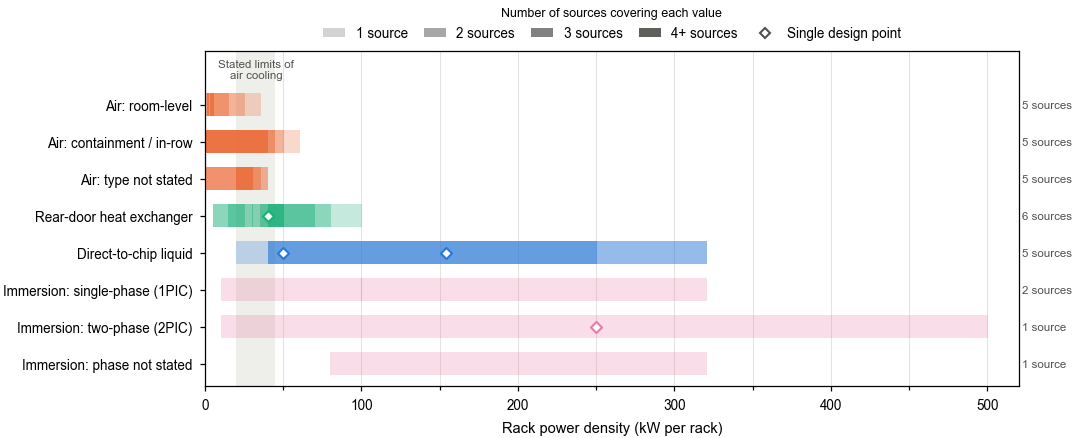

In [6]:
GRID_X = np.arange(0, 520.5, 0.5)
ALPHA = {1: 0.25, 2: 0.5, 3: 0.72}   # 4+ sources -> 0.92
BAND_H = 0.62

fig, ax = plt.subplots(figsize=(ps.TEXT_W, 2.9))
ax.axvspan(*AIR_LIMIT, color=ps.GRID, alpha=0.6, lw=0, zorder=0)
ax.text(sum(AIR_LIMIT) / 2, -0.95, 'Stated limits of\nair cooling', ha='center', va='center', fontsize=5.5, color=ps.TEXT_2)

for yi, band in enumerate(BAND_ORDER):
    rows = bands[bands['band'] == band]
    color = C_FAM[rows['family'].iloc[0]]
    count = np.zeros_like(GRID_X)
    for iv in rows['interval'].dropna():
        count += (GRID_X >= iv[0]) & (GRID_X <= iv[1])
    # draw runs of constant source count as rectangles
    edges = np.flatnonzero(np.diff(count)) + 1
    for seg in np.split(np.arange(len(GRID_X)), edges):
        n = int(count[seg[0]])
        if n:
            ax.broken_barh([(GRID_X[seg[0]], GRID_X[seg[-1]] - GRID_X[seg[0]] + 0.5)], (yi - BAND_H / 2, BAND_H),
                           facecolor=color, alpha=ALPHA.get(n, 0.92), edgecolor='none', zorder=2)
    for typ in rows['kW_typical'].dropna():   # single design points
        ax.scatter(typ, yi, marker='D', s=14, color='white', edgecolor=color, linewidth=1, zorder=4)
    n_src = rows['source'].nunique()
    ax.text(522, yi, f'{n_src} source{"s" if n_src > 1 else ""}', va='center', ha='left', fontsize=5.5, color=ps.TEXT_2)

ax.set_xlim(0, 520)
ax.xaxis.set_major_locator(MultipleLocator(100))
ax.xaxis.set_minor_locator(MultipleLocator(50))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_xlabel('Rack power density (kW per rack)')
ax.set_ylim(len(BAND_ORDER) - 0.4, -1.45)
ax.set_yticks(range(len(BAND_ORDER)))
ax.set_yticklabels(BAND_ORDER, fontsize=6.5)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', which='both', color=ps.GRID, lw=0.5)

shade = [Patch(facecolor=ps.TEXT_2, alpha=a, edgecolor='none', label=l)
         for l, a in [('1 source', 0.25), ('2 sources', 0.5), ('3 sources', 0.72), ('4+ sources', 0.92)]]
shade.append(Line2D([], [], ls='', marker='D', ms=3.5, mfc='white', mec=ps.TEXT_2, mew=1, label='Single design point'))
ax.legend(handles=shade, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=5, frameon=False,
          handlelength=1.6, columnspacing=1.2, borderaxespad=0.4, title='Number of sources covering each value',
          title_fontsize=6)

fig.savefig(OUT / 'fig3_cooling_bands.pdf')
fig.savefig(OUT / 'fig3_cooling_bands.png', dpi=600)
fig.savefig(OUT / 'fig3_cooling_bands.svg')
plt.show()